# Post 05 — Declare the null before you look

*On daily SPY, does frozen, zero-shot Chronos-2 forecast h-day log returns better than a
no-change forecast, once the loss, the family of comparisons and the multiplicity correction
are fixed before the data is seen?*

Everything here follows the frozen plan in [PREREGISTRATION.md](PREREGISTRATION.md) (modelled
on Upadhyay 2026, arXiv:2611.12141). Anything not listed there is labelled **post hoc**.

The notebook has three stages:

1. **Seen window** (2024-07-22 → 2026-07-20, Post 04's test origins): exploratory. This is
   where Post 04's h = 20 "win" lives, and where the multiplicity, level-correlation and drift
   lessons are shown.
2. **Detection limits** (planted-signal series built from pre-test SPY volatility): what a
   test of this size could even see. Run and committed *before* the blind window is opened.
3. **Blind window** (every SPY close after 2026-08-17): confirmatory, opened **once**. It runs
   only when `OPEN_BLIND = True`, which is allowed only after the code freeze is pushed
   (PREREGISTRATION §9, step 3) and only at full scale.

All forecasters work on **log price**, so the shared harness's absolute error *is* the
absolute error on the h-day log return, and the naive forecast *is* no-change.

In [1]:
import sys
import time
import warnings

sys.path.insert(0, "../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_spy
from src.evaluation import rolling_origin_evaluate
from src.null_testing import (
    NO_CHANGE,
    SMI_RATIO,
    RidgeReturnForecaster,
    add_return_columns,
    cell_table,
    chronos_price_forecast,
    chronos_return_forecast,
    chronos_standardised_forecast,
    descriptive_table,
    drift_forecast,
    family_loss_differentials,
    fit_return_ridge,
    fit_ridge_fixed_alpha,
    mae_ratio_with_ci,
    no_change_forecast,
    oracle_forecast,
    planted_sign_series,
    smi_block_length,
    spa_test,
    valid_positions,
    wilson_interval,
)

warnings.filterwarnings("ignore")
RESULTS_DIR = "../../results/05-declare-the-null"

## Configuration

`SMALL_SCALE = True` is a few-minute smoke test (40 seen origins, 3 planted realisations, fewer
bootstrap reps). **Flip it to `False` for the numbers used in the post**: 500 seen origins, 20
realisations per δ, 2,000 bootstrap reps and 1,000 SPA reps, exactly as registered.

In [2]:
SMALL_SCALE = True

# Blind stage (PREREGISTRATION §9 step 3): flip ONCE, only after the code freeze is pushed,
# and only with SMALL_SCALE = False. BLIND_FILE is the file written by
#   python -m src.dataimport --dataset spy --out spy_blind_<fetch-date>.csv
OPEN_BLIND = False
BLIND_FILE = None

SEED = 20261118
CONTEXT = 512                       # Chronos-2 context, and the drift control's window
HORIZONS = [1, 5, 20]               # seen window and descriptive blind rows
FAMILY_HORIZONS = [1, 5]            # confirmatory family on the blind window
RIDGE_ALPHAS = [0.1, 1.0, 10.0, 100.0, 1e3, 1e4]
DELTAS = [0.05, 0.1, 0.2, 0.3]      # planted sign persistence is 0.5 + delta
BLIND_SIZE = 65                     # registered blind-size origin count for the detection check
PLANTED_FIT, PLANTED_VAL = 1000, 250

if SMALL_SCALE:
    SEEN_ORIGINS = 40
    N_REALISATIONS = 3
    N_BOOT, SPA_REPS = 500, 300
    DETECTION_SIZES = {"blind": (BLIND_SIZE, FAMILY_HORIZONS)}
else:
    SEEN_ORIGINS = 500
    N_REALISATIONS = 20
    N_BOOT, SPA_REPS = 2000, 1000
    DETECTION_SIZES = {"blind": (BLIND_SIZE, FAMILY_HORIZONS), "seen": (500, HORIZONS)}

SUFFIX = "" if SMALL_SCALE else "_fullscale"
if OPEN_BLIND:
    assert not SMALL_SCALE, "the blind window is opened once, at full scale only"
    assert BLIND_FILE, "set BLIND_FILE to the freshly fetched file"

CHRONOS = {
    "Chronos-2 R0 price": chronos_price_forecast,
    "Chronos-2 R1 returns": chronos_return_forecast,
    "Chronos-2 R2 vol-std": chronos_standardised_forecast,
}
# Fixed categorical order (validated palette); no-change is the neutral reference.
COLORS = {
    "Chronos-2 R0 price": "#2a78d6",
    "Chronos-2 R1 returns": "#eb6834",
    "Chronos-2 R2 vol-std": "#1baf7a",
    "Drift": "#eda100",
    "Ridge": "#6250d6",
    "Oracle": "#52514e",
    NO_CHANGE: "#8a8984",
}

## Data and windows

Window boundaries come straight from PREREGISTRATION §2 (they are Post 04's SPY splits).
`spy.csv` must end at the last seen close, 2026-08-17; nothing after it is in the repo until the
blind fetch.

In [3]:
spy = load_spy()
logp = np.log(spy)
values = logp.to_numpy()


def pos(date, index=logp.index):
    return index.get_loc(pd.Timestamp(date))


FIT_END, VAL_START, VAL_END = "2022-07-22", "2022-07-25", "2024-07-19"
SEEN_START, SEEN_END, LAST_SEEN_CLOSE = "2024-07-22", "2026-07-20", "2026-08-17"
assert str(logp.index[-1].date()) == LAST_SEEN_CLOSE, "spy.csv must stop at the last seen close"

first_seen = pos(SEEN_START) + 1    # harness origins are train sizes: origin date = index[p - 1]
seen_series = logp.iloc[: first_seen + SEEN_ORIGINS - 1 + max(HORIZONS)]
print(f"{len(logp):,} daily closes, {logp.index[0].date()} -> {logp.index[-1].date()}")

8,444 daily closes, 1993-01-29 -> 2026-08-17


## The ridge comparator

A per-horizon ridge on the last 20 log returns plus their 5- and 20-day sums. It is fit on the
Fit window, α is chosen by validation MAE (validation-only tuning), and then it is frozen.
It sits outside the confirmatory family: it answers *does Chronos-2 add anything over a cheap
model with the same information?*

In [4]:
ridge_models, ridge_alpha, ridge_scores = {}, {}, {}
for h in HORIZONS:
    fit_positions = valid_positions(1, pos(FIT_END), h)
    val_positions = valid_positions(pos(VAL_START) + 1, pos(VAL_END), h)
    ridge_models[h], ridge_alpha[h], ridge_scores[h] = fit_return_ridge(
        values, fit_positions, val_positions, h, RIDGE_ALPHAS)

print("alpha chosen on validation:", ridge_alpha)
pd.DataFrame(ridge_scores).rename_axis("alpha").rename(columns=lambda h: f"val MAE h={h}")

alpha chosen on validation: {1: 10000.0, 5: 10000.0, 20: 10000.0}


,val MAE h=1,val MAE h=5,val MAE h=20
alpha,,,
0.1,0.007470,0.016127,0.034442
1.0,0.007470,0.016127,0.034442
10.0,0.007470,0.016127,0.034442
100.0,0.007467,0.016125,0.034441
1000.0,0.007446,0.016108,0.034427
10000.0,0.007358,0.016040,0.034373


## Stage 1 — the seen window (exploratory)

Every forecaster runs through the shared harness on identical origins and horizons:
no-change, the two ingredient controls (drift over the same 512 days Chronos-2 sees, and the
ridge), and Chronos-2 with three inputs (R0 price levels, R1 log returns, R2 volatility-
standardised returns).

In [5]:
def forecasters(ridge):
    models = {
        NO_CHANGE: (no_change_forecast, {}),
        "Drift": (drift_forecast, {"context_length": CONTEXT}),
        "Ridge": (ridge, {}),
    }
    models.update({name: (fn, {"max_context_length": CONTEXT}) for name, fn in CHRONOS.items()})
    return models


def run_all(series, first_origin, horizons, models):
    frames = []
    for name, (fn, kwargs) in models.items():
        start = time.perf_counter()
        frames.append(rolling_origin_evaluate(series, fn, name, horizons, first_origin,
                                              model_kwargs=kwargs))
        print(f"  {name:<24} {time.perf_counter() - start:7.1f}s")
    return pd.concat(frames, ignore_index=True)


seen = run_all(seen_series, first_seen, HORIZONS, forecasters(RidgeReturnForecaster(ridge_models)))
print(f"{seen['origin'].nunique()} origins: {seen['origin'].min().date()} -> {seen['origin'].max().date()}")

  No-change                    0.0s
  Drift                        0.0s
  Ridge                        0.1s


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

  Chronos-2 R0 price          17.4s


  Chronos-2 R1 returns         4.3s


  Chronos-2 R2 vol-std         4.5s
40 origins: 2024-07-22 -> 2024-09-16


### MAE ratio against no-change, with the smallest meaningful improvement

`mae_ratio = Σ|y − f| / Σ|y|`; below 1 favours the model. A cell "beats no-change" only if the
ratio is ≤ 0.995 **and** the upper end of its 95% paired block-bootstrap interval is below 1.
MASE is shown for continuity with Posts 01–04.

In [6]:
seen_cells = cell_table(seen, n_boot=N_BOOT, seed=SEED)
seen_cells.round(4)

,model,horizon,n,mae_ratio,ratio_low,ratio_high,meets_smi,mase
0,Chronos-2 R0 price,1,40,1.0036,0.9436,1.0617,False,1.0972
1,Chronos-2 R0 price,5,40,0.9509,0.8942,1.0072,False,2.7328
2,Chronos-2 R0 price,20,40,0.6434,0.5875,0.6998,True,2.4542
3,Chronos-2 R1 returns,1,40,1.0024,0.9688,1.0343,False,1.0959
4,Chronos-2 R1 returns,5,40,0.9907,0.9088,1.0676,False,2.8473
5,Chronos-2 R1 returns,20,40,0.5933,0.5123,0.6731,True,2.2631
6,Chronos-2 R2 vol-std,1,40,0.9936,0.9375,1.0467,False,1.0862
7,Chronos-2 R2 vol-std,5,40,0.9740,0.8390,1.1142,False,2.7993
8,Chronos-2 R2 vol-std,20,40,0.4887,0.3542,0.6223,True,1.8643
9,Drift,1,40,0.9922,0.9661,1.0178,False,1.0847


### D1 — more tickets, more winners

Count how many of the 9 Chronos-2 cells (3 inputs × 3 horizons) clear the bar *one at a time*,
then ask the question SPA asks: is the best of them better than no-change, after paying for
having picked the best? On the seen window SPA runs over all 9 cells with a mean block of 20
days (exploratory).

In [7]:
seen_family = [(m, h) for m in CHRONOS for h in HORIZONS]
seen_wins = seen_cells[seen_cells["model"].isin(CHRONOS) & seen_cells["meets_smi"]]
seen_spa = spa_test(family_loss_differentials(seen, seen_family), block_size=max(HORIZONS),
                    reps=SPA_REPS, seed=SEED)
print(f"{len(seen_wins)} of {len(seen_family)} Chronos-2 cells meet the SMI pairwise")
pd.Series(seen_spa)

3 of 9 Chronos-2 cells meet the SMI pairwise


n_origins                                         40
n_cells                                            9
block_size                                        20
reps                                             300
best_cell                Chronos-2 R2 vol-std | h=20
best_mean_d                                 0.015309
statistic_is_zero                              False
p_consistent                                     0.0
p_lower                                          0.0
p_upper                                          0.0
p_consistent_arch_raw                            0.0
p_lower_arch_raw                                 0.0
p_upper_arch_raw                                 0.0
dtype: object

### D2 — re-examining Post 04's h = 20 "win"

First reproduce Post 04's own comparison from its saved forecasts (scaled error on price
levels), then check that this notebook's R0 forecasts are the same forecasts, then re-score them
as a return MAE ratio and against **drift**, the ingredient control.

In [8]:
p04 = pd.read_csv("../../results/04-online-residual-correction/metrics/"
                  "online_correction_test_forecasts_fullscale.csv", dtype={"origin": str})
p04 = p04[p04["horizon"].isin(HORIZONS)].copy()          # SPY rows (CISO uses 6/24/168)
p04["origin"] = pd.to_datetime(p04["origin"])

p04_h20 = p04[p04["horizon"] == 20].pivot_table(index="origin", columns="model",
                                                values="scaled_absolute_error")
frozen, naive = p04_h20["Chronos-2 (frozen)"], p04_h20["Naive"]
p04_pct = 100 * (naive.mean() - frozen.mean()) / frozen.mean()
print(f"Post 04, h=20: naive's scaled error is {p04_pct:+.1f}% vs frozen Chronos-2 (n={len(p04_h20)})")

ours = seen[seen["model"] == "Chronos-2 R0 price"]
same = ours.merge(p04[p04["model"] == "Chronos-2 (frozen)"][["origin", "horizon", "forecast"]],
                  on=["origin", "horizon"], suffixes=("", "_p04"))
max_rel = float((np.exp(same["forecast"]) / same["forecast_p04"] - 1).abs().max())
print(f"R0 vs Post 04 frozen forecasts on {len(same)} shared rows: max relative difference {max_rel:.2e}")


def versus(results, model, comparator, horizon):
    pick = lambda name: add_return_columns(
        results[(results["model"] == name) & (results["horizon"] == horizon)]).sort_values("origin")
    a, b = pick(model), pick(comparator)
    assert (a["origin"].to_numpy() == b["origin"].to_numpy()).all()
    stats = mae_ratio_with_ci(a["loss"].to_numpy(), b["loss"].to_numpy(),
                              smi_block_length(horizon), n_boot=N_BOOT, seed=SEED)
    return {"model": model, "comparator": comparator, "horizon": horizon,
            "loss_ratio": stats["mae_ratio"], "ratio_low": stats["ratio_low"],
            "ratio_high": stats["ratio_high"]}


d2 = pd.DataFrame([versus(seen, "Chronos-2 R0 price", NO_CHANGE, 20),
                   versus(seen, "Drift", NO_CHANGE, 20),
                   versus(seen, "Chronos-2 R0 price", "Drift", 20)])
d2.round(4)

Post 04, h=20: naive's scaled error is +11.8% vs frozen Chronos-2 (n=500)
R0 vs Post 04 frozen forecasts on 120 shared rows: max relative difference 4.44e-16


,model,comparator,horizon,loss_ratio,ratio_low,ratio_high
0,Chronos-2 R0 price,No-change,20,0.6434,0.5875,0.6998
1,Drift,No-change,20,0.6136,0.5847,0.6432
2,Chronos-2 R0 price,Drift,20,1.0484,0.9843,1.1157


### D6 — every Chronos-2 cell against the two ingredient controls

Ratios below 1 mean Chronos-2 had lower absolute return error than the comparator.

In [9]:
seen_vs_controls = pd.DataFrame([versus(seen, m, c, h) for m in CHRONOS for c in ["Drift", "Ridge"]
                                 for h in HORIZONS])
seen_vs_controls.round(4)

,model,comparator,horizon,loss_ratio,ratio_low,ratio_high
0,Chronos-2 R0 price,Drift,1,1.0115,0.9645,1.0578
1,Chronos-2 R0 price,Drift,5,0.9807,0.9449,1.0184
2,Chronos-2 R0 price,Drift,20,1.0484,0.9843,1.1157
3,Chronos-2 R0 price,Ridge,1,0.9931,0.9396,1.0471
4,Chronos-2 R0 price,Ridge,5,0.9627,0.9336,0.9943
5,Chronos-2 R0 price,Ridge,20,0.8533,0.8102,0.8950
6,Chronos-2 R1 returns,Drift,1,1.0103,1.0009,1.0221
7,Chronos-2 R1 returns,Drift,5,1.0217,0.9991,1.0483
8,Chronos-2 R1 returns,Drift,20,0.9668,0.8540,1.0779
9,Chronos-2 R1 returns,Ridge,1,0.9920,0.9605,1.0247


### D3–D5 — three ways a forecast can look skilful without being skilful

- **Price-level correlation**: forecast price against realised price. "Same as today" scores
  highly on this because tomorrow's price is mostly today's price.
- **Directional accuracy against the up-day base rate** (what "always up" scores), not 50%.
  Overlapping targets make the binomial p-value optimistic, so it is descriptive.
- **Dispersion ratio**: how much the forecast returns move relative to the realised returns
  (the single-series version of Forecast Collapse's flatness check).

In [10]:
seen_desc = descriptive_table(seen)
seen_desc.round(4)

,model,horizon,n,price_level_corr,up_base_rate,dispersion_ratio,directional_accuracy,binom_p_vs_base_rate
0,Chronos-2 R0 price,1,40,0.8569,0.60,0.2128,0.450,0.9811
1,Chronos-2 R0 price,5,40,0.3806,0.65,0.1012,0.675,0.4408
2,Chronos-2 R0 price,20,40,0.7661,1.00,0.2421,1.000,1.0000
3,Chronos-2 R1 returns,1,40,0.8767,0.60,0.0293,0.575,0.6885
4,Chronos-2 R1 returns,5,40,0.3667,0.65,0.0584,0.625,0.6946
5,Chronos-2 R1 returns,20,40,0.7445,1.00,0.3647,0.975,1.0000
6,Chronos-2 R2 vol-std,1,40,0.8785,0.60,0.0351,0.575,0.6885
7,Chronos-2 R2 vol-std,5,40,0.3994,0.65,0.0607,0.650,0.5721
8,Chronos-2 R2 vol-std,20,40,0.7350,1.00,0.4047,1.000,1.0000
9,Drift,1,40,0.8772,0.60,0.0058,0.600,0.5681


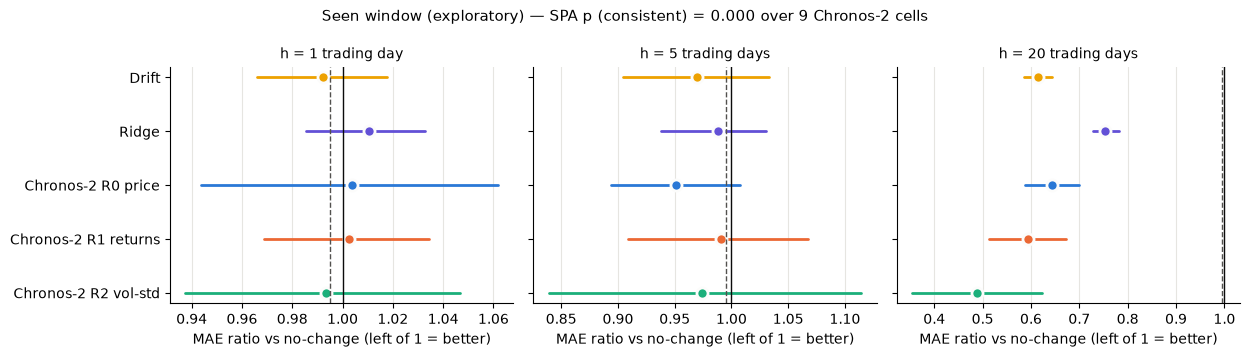

In [11]:
def forest(cells, spa, title, path, horizons):
    order = ["Drift", "Ridge"] + list(CHRONOS)
    fig, axes = plt.subplots(1, len(horizons), figsize=(4.2 * len(horizons), 3.6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, h in zip(axes, horizons):
        rows = cells[cells["horizon"] == h].set_index("model").reindex(order)
        y = np.arange(len(order))[::-1]
        for yi, (name, row) in zip(y, rows.iterrows()):
            ax.plot([row["ratio_low"], row["ratio_high"]], [yi, yi], color=COLORS[name], lw=2,
                    solid_capstyle="round")
            ax.plot(row["mae_ratio"], yi, "o", ms=8, color=COLORS[name], mec="#fcfcfb", mew=2)
        ax.axvline(1.0, color="#0b0b0b", lw=1)
        ax.axvline(SMI_RATIO, color="#52514e", lw=1, ls="--")
        ax.set_yticks(y, order)
        ax.set_title(f"h = {h} trading day{'s' if h > 1 else ''}", fontsize=10)
        ax.set_xlabel("MAE ratio vs no-change (left of 1 = better)")
        ax.grid(axis="x", color="#e6e5e1", lw=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    fig.suptitle(f"{title} — SPA p (consistent) = {spa['p_consistent']:.3f} over "
                 f"{spa['n_cells']} Chronos-2 cells", fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


forest(seen_cells, seen_spa, "Seen window (exploratory)",
       f"{RESULTS_DIR}/figures/seen_mae_ratio{SUFFIX}.png", HORIZONS)

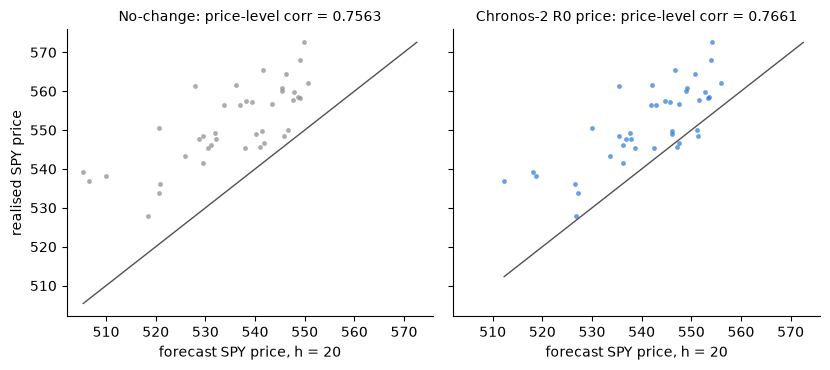

In [12]:
def level_scatter(results, horizon, path):
    names = [NO_CHANGE, "Chronos-2 R0 price"]
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.8), sharex=True, sharey=True)
    for ax, name in zip(axes, names):
        rows = results[(results["model"] == name) & (results["horizon"] == horizon)]
        actual, forecast = np.exp(rows["actual"]), np.exp(rows["forecast"])
        corr = np.corrcoef(forecast, actual)[0, 1]
        ax.scatter(forecast, actual, s=12, color=COLORS[name], alpha=0.7, linewidths=0)
        lims = [min(actual.min(), forecast.min()), max(actual.max(), forecast.max())]
        ax.plot(lims, lims, color="#52514e", lw=1)
        ax.set_title(f"{name}: price-level corr = {corr:.4f}", fontsize=10)
        ax.set_xlabel(f"forecast SPY price, h = {horizon}")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0].set_ylabel("realised SPY price")
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


level_scatter(seen, 20, f"{RESULTS_DIR}/figures/seen_price_level{SUFFIX}.png")

In [13]:
seen_cells.to_csv(f"{RESULTS_DIR}/metrics/seen_cells{SUFFIX}.csv", index=False)
pd.DataFrame([seen_spa]).to_csv(f"{RESULTS_DIR}/metrics/seen_spa{SUFFIX}.csv", index=False)
d2.assign(post04_naive_pct_vs_frozen=p04_pct, r0_matches_post04_max_rel=max_rel).to_csv(
    f"{RESULTS_DIR}/metrics/seen_post04_h20{SUFFIX}.csv", index=False)
seen_vs_controls.to_csv(f"{RESULTS_DIR}/metrics/seen_vs_controls{SUFFIX}.csv", index=False)
seen_desc.to_csv(f"{RESULTS_DIR}/metrics/seen_descriptive{SUFFIX}.csv", index=False)
seen.to_csv(f"{RESULTS_DIR}/metrics/seen_forecasts{SUFFIX}.csv", index=False)

## Stage 2 — detection limits (before the blind window is opened)

*What could a test of this size even see?* Each planted series keeps SPY's real absolute daily
returns from the pre-test period and replaces the signs with a Markov chain that repeats the
previous sign with probability 0.5 + δ. A forecaster "detects" the signal if it meets the same
SMI used on real data. The **oracle** knows δ and forecasts the conditional mean exactly, so its
detection rate is the ceiling. The ridge is refit on each planted series (fit / validation
slices, then frozen). Chronos-2 (R1) runs at blind size only, to bound runtime.

The detection limit is the smallest δ at which the oracle detects in at least 80% of
realisations. Edges smaller than that are *not excluded* by a null result.

In [14]:
real_abs_returns = np.abs(np.diff(values[: pos(VAL_END) + 1]))   # pre-test magnitudes only


def detection_run(delta, n_eval, horizons, rng, with_chronos):
    max_h = max(horizons)
    n_returns = PLANTED_FIT + PLANTED_VAL + n_eval + max_h
    series = planted_sign_series(real_abs_returns[-n_returns:], delta, rng)
    planted = series.to_numpy()
    first = PLANTED_FIT + PLANTED_VAL + 1
    series = series.iloc[: first + n_eval - 1 + max_h]

    ridge = {}
    for h in horizons:
        ridge[h], _, _ = fit_return_ridge(
            planted, valid_positions(1, PLANTED_FIT, h),
            valid_positions(PLANTED_FIT + 1, PLANTED_FIT + PLANTED_VAL, h), h, RIDGE_ALPHAS)

    models = {
        NO_CHANGE: (no_change_forecast, {}),
        "Oracle": (oracle_forecast, {"delta": delta, "magnitude_window": CONTEXT}),
        "Ridge": (RidgeReturnForecaster(ridge), {}),
    }
    if with_chronos:
        models["Chronos-2 R1 returns"] = (chronos_return_forecast, {"max_context_length": CONTEXT})
    results = pd.concat([rolling_origin_evaluate(series, fn, name, horizons, first, model_kwargs=kw)
                         for name, (fn, kw) in models.items()], ignore_index=True)
    return cell_table(results, n_boot=N_BOOT, seed=SEED)


rng = np.random.default_rng(SEED)
runs = []
start = time.perf_counter()
for size, (n_eval, horizons) in DETECTION_SIZES.items():
    for delta in DELTAS:
        for k in range(N_REALISATIONS):
            table = detection_run(delta, n_eval, horizons, rng, with_chronos=(size == "blind"))
            runs.append(table.assign(size=size, n_eval=n_eval, delta=delta, realisation=k))
        print(f"  {size:<5} delta={delta:<4}  {time.perf_counter() - start:7.1f}s")
detection_raw = pd.concat(runs, ignore_index=True)

detection = (detection_raw.groupby(["size", "n_eval", "model", "horizon", "delta"])
             .agg(detections=("meets_smi", "sum"), runs=("meets_smi", "size"),
                  mean_ratio=("mae_ratio", "mean"))
             .reset_index())
detection["rate"] = detection["detections"] / detection["runs"]
bounds = [wilson_interval(d, n) for d, n in zip(detection["detections"], detection["runs"])]
detection["rate_low"], detection["rate_high"] = zip(*bounds)


def oracle_limit(group):
    hit = group[group["rate"] >= 0.8]["delta"]
    return f"{hit.min():g}" if len(hit) else f"> {max(DELTAS):g}"


detection_limits = (detection[detection["model"] == "Oracle"]
                    .groupby(["size", "n_eval", "horizon"]).apply(oracle_limit)
                    .rename("oracle_detection_limit_delta").reset_index())
detection_limits

  blind delta=0.05     21.9s


  blind delta=0.1      43.5s


  blind delta=0.2      65.3s


  blind delta=0.3      86.5s


,size,n_eval,horizon,oracle_detection_limit_delta
0,blind,65,1,> 0.3
1,blind,65,5,> 0.3


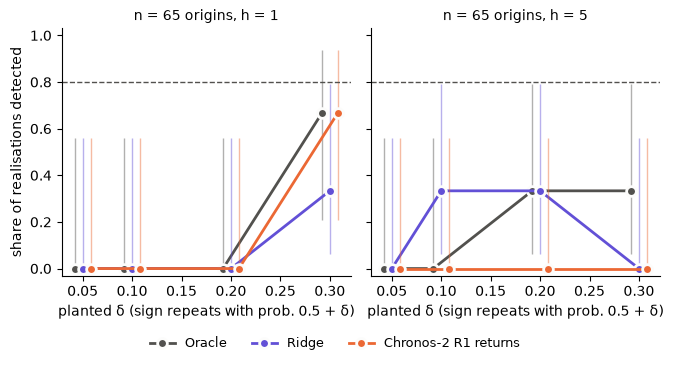

In [15]:
def detection_plot(detection, path):
    panels = detection[["size", "n_eval", "horizon"]].drop_duplicates().sort_values(["n_eval", "horizon"])
    fig, axes = plt.subplots(1, len(panels), figsize=(3.4 * len(panels), 3.4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (_, panel) in zip(axes, panels.iterrows()):
        sub = detection[(detection["size"] == panel["size"]) & (detection["horizon"] == panel["horizon"])]
        for offset, name in zip([-0.008, 0.0, 0.008], ["Oracle", "Ridge", "Chronos-2 R1 returns"]):
            rows = sub[sub["model"] == name].sort_values("delta")
            if rows.empty:
                continue
            x = rows["delta"] + offset          # small dodge so coincident series stay visible
            ax.vlines(x, rows["rate_low"], rows["rate_high"], color=COLORS[name], lw=1, alpha=0.45)
            ax.plot(x, rows["rate"], color=COLORS[name], lw=2, marker="o", ms=7,
                    mec="#fcfcfb", mew=2, label=name)
        ax.axhline(0.8, color="#52514e", lw=1, ls="--")
        ax.set_title(f"n = {panel['n_eval']} origins, h = {panel['horizon']}", fontsize=10)
        ax.set_xlabel("planted δ (sign repeats with prob. 0.5 + δ)")
        ax.set_ylim(-0.03, 1.03)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0].set_ylabel("share of realisations detected")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, fontsize=9, ncol=len(labels),
               loc="lower center", bbox_to_anchor=(0.5, -0.08))
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


detection_plot(detection, f"{RESULTS_DIR}/figures/detection_limits{SUFFIX}.png")
detection_raw.to_csv(f"{RESULTS_DIR}/metrics/detection_raw{SUFFIX}.csv", index=False)
detection.to_csv(f"{RESULTS_DIR}/metrics/detection_summary{SUFFIX}.csv", index=False)
detection_limits.to_csv(f"{RESULTS_DIR}/metrics/detection_limits{SUFFIX}.csv", index=False)

## Stage 3 — the blind window (confirmatory, opened once)

Runs only with `OPEN_BLIND = True`, at full scale, after the code freeze is pushed. Steps:

1. Fetch: `python -m src.dataimport --dataset spy --out spy_blind_<fetch-date>.csv`
   (prints nothing; do not open the file).
2. Set `BLIND_FILE`, flip `OPEN_BLIND`, run all cells once, and commit the outputs unedited.

**Confirmatory family:** {R0, R1, R2} × {h = 1, h = 5}, six cells. Verdict "Chronos-2 shows
skill over no-change on daily SPY" only if SPA's consistent p < 0.05 **and** at least one of
the six cells meets the SMI. h = 20 is scored but descriptive only.

In [16]:
if OPEN_BLIND:
    blind_logp = np.log(load_spy(BLIND_FILE))
    overlap = logp.index.intersection(blind_logp.index)
    overlap_diff = float(np.max(np.abs(np.diff(logp.loc[overlap].to_numpy())
                                       - np.diff(blind_logp.loc[overlap].to_numpy()))))
    print(f"overlap check: max |difference in daily log return| = {overlap_diff:.2e} "
          f"({'OK' if overlap_diff < 1e-4 else 'FAILS the registered 1e-4 check -- report it'})")

    blind_values = blind_logp.to_numpy()
    first_blind = pos(LAST_SEEN_CLOSE, blind_logp.index) + 1
    blind_ridge = {h: fit_ridge_fixed_alpha(blind_values, valid_positions(1, first_blind - 1, h),
                                            h, ridge_alpha[h]) for h in HORIZONS}
    blind_models = forecasters(RidgeReturnForecaster(blind_ridge))

    print("family run (h = 1, 5):")
    blind_family = run_all(blind_logp, first_blind, FAMILY_HORIZONS, blind_models)
    print("descriptive run (h = 20):")
    blind_h20 = run_all(blind_logp, first_blind, [20], blind_models)
    blind = pd.concat([blind_family, blind_h20], ignore_index=True)
    print(f"blind origins: {blind_family['origin'].min().date()} -> {blind_family['origin'].max().date()} "
          f"({blind_family['origin'].nunique()} at h = 1/5; {blind_h20['origin'].nunique()} at h = 20)")
else:
    print("Blind window not opened (OPEN_BLIND = False).")

Blind window not opened (OPEN_BLIND = False).


In [17]:
if OPEN_BLIND:
    blind_cells = cell_table(blind, n_boot=N_BOOT, seed=SEED)
    family = [(m, h) for m in CHRONOS for h in FAMILY_HORIZONS]
    blind_spa = spa_test(family_loss_differentials(blind_family, family), block_size=5,
                         reps=SPA_REPS, seed=SEED)
    family_rows = blind_cells[blind_cells["model"].isin(CHRONOS)
                              & blind_cells["horizon"].isin(FAMILY_HORIZONS)]
    skill = blind_spa["p_consistent"] < 0.05 and bool(family_rows["meets_smi"].any())
    print("VERDICT:", "Chronos-2 shows skill over no-change on daily SPY" if skill else
          "no skill detected; edges smaller than the detection limit are not excluded")
    print(f"  SPA consistent p = {blind_spa['p_consistent']:.3f} over {blind_spa['n_cells']} cells, "
          f"{blind_spa['n_origins']} origins; cells meeting the SMI: {int(family_rows['meets_smi'].sum())}")
    display(blind_cells.round(4))
    display(pd.Series(blind_spa))

In [18]:
if OPEN_BLIND:
    blind_desc = descriptive_table(blind)
    blind_vs_controls = pd.DataFrame([versus(blind, m, c, h) for m in CHRONOS
                                      for c in ["Drift", "Ridge"] for h in HORIZONS])
    display(blind_desc.round(4))
    display(blind_vs_controls.round(4))
    forest(blind_cells, blind_spa, "Blind window (confirmatory: h = 1, 5)",
           f"{RESULTS_DIR}/figures/blind_mae_ratio{SUFFIX}.png", HORIZONS)

    blind_cells.to_csv(f"{RESULTS_DIR}/metrics/blind_cells{SUFFIX}.csv", index=False)
    pd.DataFrame([{**blind_spa, "verdict_skill": skill, "overlap_max_abs_diff": overlap_diff,
                   "blind_file": BLIND_FILE}]).to_csv(
        f"{RESULTS_DIR}/metrics/blind_spa{SUFFIX}.csv", index=False)
    blind_desc.to_csv(f"{RESULTS_DIR}/metrics/blind_descriptive{SUFFIX}.csv", index=False)
    blind_vs_controls.to_csv(f"{RESULTS_DIR}/metrics/blind_vs_controls{SUFFIX}.csv", index=False)
    blind.to_csv(f"{RESULTS_DIR}/metrics/blind_forecasts{SUFFIX}.csv", index=False)

## The registered predictions, side by side with what happened

PREREGISTRATION §8, quoted, next to the numbers that bear on each. They are shown, not
auto-graded: where the registered wording is qualitative ("mostly disappears"), the judgment is
made in the write-up, in the open.

In [19]:
def price_corr_summary(desc):
    out = []
    for h, g in desc.groupby("horizon"):
        top = g.loc[g["price_level_corr"].idxmax(), "model"]
        out.append(f"h={h}: min corr {g['price_level_corr'].min():.4f}, highest = {top}")
    return "; ".join(out)


r0_vs_drift = d2[(d2["model"] == "Chronos-2 R0 price") & (d2["comparator"] == "Drift")].iloc[0]
predictions = [
    ("P1", "No cell in C meets the SMI on the blind window, and SPA does not reject.",
     (f"SMI cells = {int(family_rows['meets_smi'].sum())}, SPA p = {blind_spa['p_consistent']:.3f}")
     if OPEN_BLIND else "blind window not opened"),
    ("P2", "The detection limit at blind size is large (oracle needs delta >= 0.2 or more).",
     "; ".join(f"h={r.horizon}: {r.oracle_detection_limit_delta}"
               for r in detection_limits[detection_limits["size"] == "blind"].itertuples())),
    ("P3", "On the seen window at least one of the 9 cells 'wins' pairwise, but the 9-cell SPA does not reject.",
     f"pairwise wins = {len(seen_wins)}, SPA p = {seen_spa['p_consistent']:.3f}"),
    ("P4", "Post 04's h = 20 advantage over naive mostly disappears against drift.",
     f"R0/drift loss ratio at h=20 = {r0_vs_drift['loss_ratio']:.3f} "
     f"[{r0_vs_drift['ratio_low']:.3f}, {r0_vs_drift['ratio_high']:.3f}]"),
    ("P5", "Every cell and no-change have price-level corr > 0.99; no-change highest or tied.",
     "seen: " + price_corr_summary(seen_desc)
     + (" | blind: " + price_corr_summary(blind_desc) if OPEN_BLIND else "")),
]
predictions = pd.DataFrame(predictions, columns=["id", "registered prediction", "what happened"])
predictions.to_csv(f"{RESULTS_DIR}/metrics/predictions{SUFFIX}.csv", index=False)
pd.set_option("display.max_colwidth", None)
predictions

,id,registered prediction,what happened
0,P1,"No cell in C meets the SMI on the blind window, and SPA does not reject.",blind window not opened
1,P2,The detection limit at blind size is large (oracle needs delta >= 0.2 or more).,h=1: > 0.3; h=5: > 0.3
2,P3,"On the seen window at least one of the 9 cells 'wins' pairwise, but the 9-cell SPA does not reject.","pairwise wins = 3, SPA p = 0.000"
3,P4,Post 04's h = 20 advantage over naive mostly disappears against drift.,"R0/drift loss ratio at h=20 = 1.048 [0.984, 1.116]"
4,P5,Every cell and no-change have price-level corr > 0.99; no-change highest or tied.,"seen: h=1: min corr 0.8569, highest = Chronos-2 R2 vol-std; h=5: min corr 0.3658, highest = Chronos-2 R2 vol-std; h=20: min corr 0.7350, highest = Chronos-2 R0 price"
